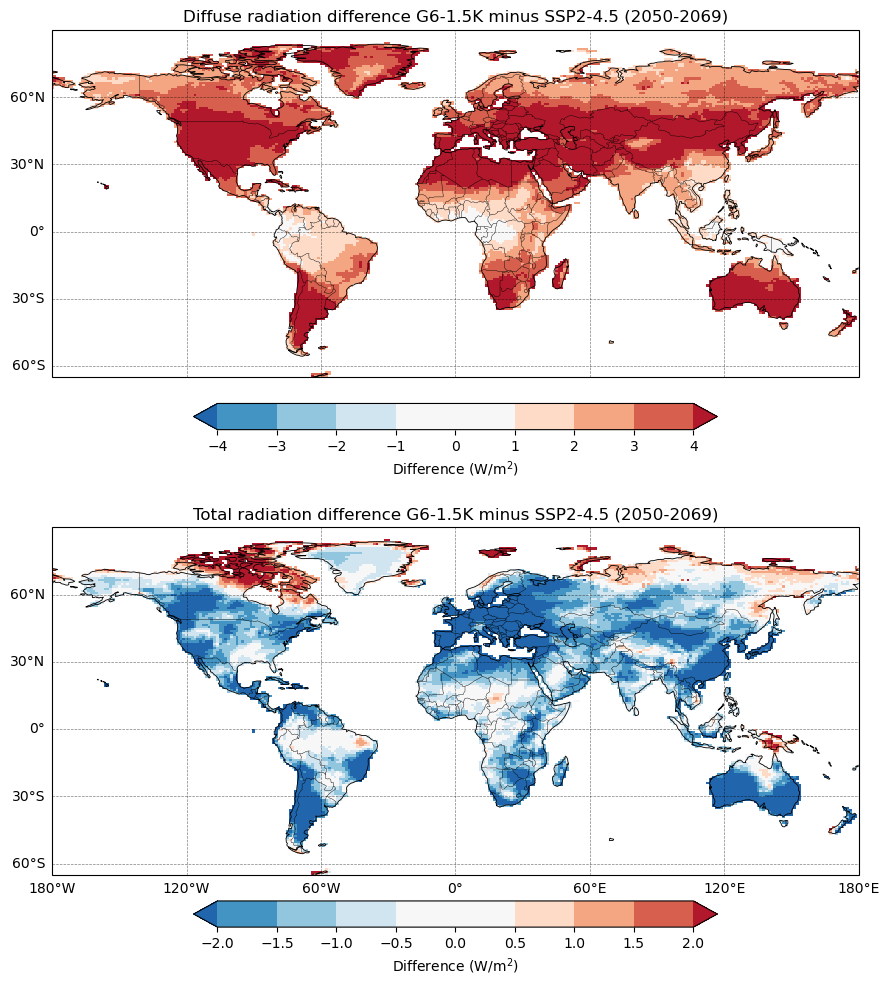

In [17]:
import pyreadr
import pandas as pd
import statsmodels.formula.api as smf
import statsmodels.api as sm
import xarray as xr
import numpy as np
import pandas as pd
from scipy.special import expit 
import os

path = '/glade/derecho/scratch/brendanc/fates_output/radiation'
ssp_dir = xr.open_dataset(path + "/b.e21.BWSSP245cmip6.f09_g17.CMIP6-SSP2-4.5-WACCM.006.clm2.h0.FSDSVD.201501-206912.nc")
ssp_dir = ssp_dir["FSDSVD"]
ssp_dif = xr.open_dataset(path + "/b.e21.BWSSP245cmip6.f09_g17.CMIP6-SSP2-4.5-WACCM.006.clm2.h0.FSDSVI.201501-206912.nc")
ssp_dif = ssp_dif["FSDSVI"]
geo_dir = xr.open_dataset(path + "/b.e21.BW.f09_g17.SSP245-G6-1p5K-SAI.001.clm2.h0.FSDSVD.203501-208412.nc")
geo_dir = geo_dir["FSDSVD"]
geo_dif = xr.open_dataset(path + "/b.e21.BW.f09_g17.SSP245-G6-1p5K-SAI.001.clm2.h0.FSDSVI.203501-208412.nc")
geo_dif = geo_dif["FSDSVI"]

tot_ssp = (ssp_dir + ssp_dif)
tot_geo = (geo_dir + geo_dif)

import xarray as xr
import numpy as np

def clim_2050_2069(da):
    # No conversion needed; xarray can slice/groupby on cftime just fine
    da_sub = da.sel(time=slice("2050-01-01", "2069-12-31"))
    clim = da_sub.groupby("time.month").mean("time", skipna=True)
    clim.attrs.update(da.attrs)
    clim.attrs["climatology_period"] = "2050-01 to 2069-12"
    return clim

ssp_dir_clim = clim_2050_2069(ssp_dir)
ssp_dif_clim = clim_2050_2069(ssp_dif)
geo_dir_clim = clim_2050_2069(geo_dir)
geo_dif_clim = clim_2050_2069(geo_dif)
tot_ssp = clim_2050_2069(tot_ssp)
tot_geo = clim_2050_2069(tot_geo)

ssp_dir_clim = ssp_dir_clim.mean(dim='month')
ssp_dif_clim = ssp_dif_clim.mean(dim='month')
geo_dir_clim = geo_dir_clim.mean(dim='month')
geo_dif_clim = geo_dif_clim.mean(dim='month')
tot_ssp = tot_ssp.mean(dim='month')
tot_geo = tot_geo.mean(dim='month')

dif_dif = (geo_dif_clim - ssp_dif_clim)
tot_dif = (tot_geo - tot_ssp)

import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.colors as mcolors
import matplotlib.ticker as mticker
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER

proj = ccrs.PlateCarree()

dif_colors = ['#2166ac',
              '#4393c3',
              '#92c5de',
              '#d1e5f0',
              '#f7f7f7',
              '#f7f7f7',
              '#fddbc7',
              '#f4a582',
              '#d6604d',
              '#b2182b']

def make_cmap_norm(vmin, vmax, step):
    levels = np.arange(vmin, vmax + step, step)
    cmap, norm = mcolors.from_levels_and_colors(
        levels, dif_colors, extend="both"
    )
    return levels, cmap, norm

dif_levels, dif_cmap, dif_norm = make_cmap_norm(vmin=-4, vmax=4, step=1)
tot_levels, tot_cmap, tot_norm = make_cmap_norm(vmin=-2, vmax=2, step=0.5)

fig, axes = plt.subplots(
    2, 1, figsize=(9, 11),
    subplot_kw={"projection": proj}
)

fields = [dif_dif, tot_dif]
titles = [
    "Diffuse radiation difference G6-1.5K minus SSP2-4.5 (2050-2069)",
    "Total radiation difference G6-1.5K minus SSP2-4.5 (2050-2069)"
]
levels_list = [dif_levels, tot_levels]
cmaps = [dif_cmap, tot_cmap]
norms = [dif_norm, tot_norm]

for i, (ax, field, title, levels, cmap, norm) in enumerate(zip(
    axes, fields, titles, levels_list, cmaps, norms
)):
    lon = field["lon"]
    lat = field["lat"]

    pcm = ax.pcolormesh(
        lon,
        lat,
        field,
        transform=ccrs.PlateCarree(),
        shading="auto",
        cmap=cmap,
        norm=norm
    )
    ax.coastlines(linewidth=0.6)
    ax.add_feature(cfeature.BORDERS, linewidth=0.3)
    ax.set_xlim(-180, 180)
    ax.set_ylim(-65, 90)
    ax.set_title(title)

    gl = ax.gridlines(crs=ccrs.PlateCarree(), linewidth=0.5,
                       color='black', alpha=0.5, linestyle='--',
                       draw_labels=True)
    gl.top_labels = False
    gl.bottom_labels = (i == 1)   # longitude labels only on bottom plot
    gl.right_labels = False
    gl.left_labels = True         # latitude labels on both (stacked column)
    gl.xlines = True
    gl.ylocator = mticker.FixedLocator([-60, -30, 0, 30, 60, 90])
    gl.xformatter = LONGITUDE_FORMATTER
    gl.yformatter = LATITUDE_FORMATTER
    gl.xlabel_style = {'color': 'black'}
    gl.ylabel_style = {'color': 'black'}

    cbar = fig.colorbar(
        pcm, ax=ax, orientation="horizontal",
        pad=0.05, fraction=0.05,
        extend="both", ticks=levels
    )
    cbar.set_label("Difference (W/m$^2$)")

plt.tight_layout()
plt.subplots_adjust(hspace=-0.05)
savedir = "/glade/derecho/scratch/brendanc/fates_output/radiation"
#plt.show()
plt.savefig(f"G6-1.5K_rad_maps.png", dpi=600, bbox_inches="tight")

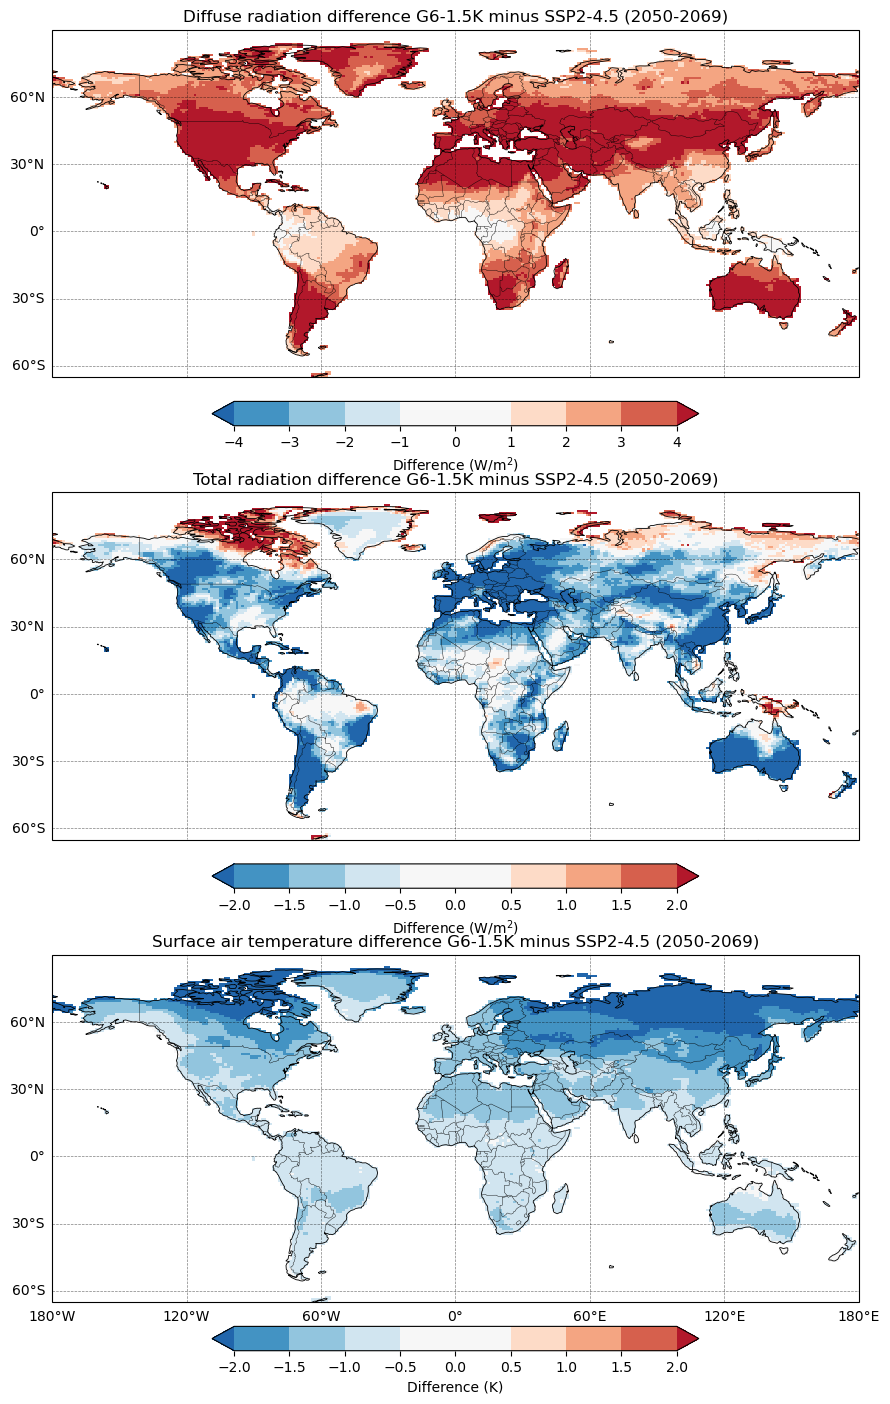

In [14]:
import pyreadr
import pandas as pd
import statsmodels.formula.api as smf
import statsmodels.api as sm
import xarray as xr
import numpy as np
from scipy.special import expit
import os

path = '/glade/derecho/scratch/brendanc/fates_output/radiation'
ssp_dir = xr.open_dataset(path + "/b.e21.BWSSP245cmip6.f09_g17.CMIP6-SSP2-4.5-WACCM.006.clm2.h0.FSDSVD.201501-206912.nc")["FSDSVD"]
ssp_dif = xr.open_dataset(path + "/b.e21.BWSSP245cmip6.f09_g17.CMIP6-SSP2-4.5-WACCM.006.clm2.h0.FSDSVI.201501-206912.nc")["FSDSVI"]
geo_dir = xr.open_dataset(path + "/b.e21.BW.f09_g17.SSP245-G6-1p5K-SAI.001.clm2.h0.FSDSVD.203501-208412.nc")["FSDSVD"]
geo_dif = xr.open_dataset(path + "/b.e21.BW.f09_g17.SSP245-G6-1p5K-SAI.001.clm2.h0.FSDSVI.203501-208412.nc")["FSDSVI"]

# ---- NEW: surface air temperature ----
ssp_tsa = xr.open_dataset(path + "/b.e21.BWSSP245cmip6.f09_g17.CMIP6-SSP2-4.5-WACCM.006.clm2.h0.TSA.201501-206912.nc")["TSA"]
geo_tsa = xr.open_dataset(path + "/b.e21.BW.f09_g17.SSP245-G6-1p5K-SAI.001.clm2.h0.TSA.203501-208412.nc")["TSA"]

tot_ssp = (ssp_dir + ssp_dif)
tot_geo = (geo_dir + geo_dif)   # <-- fixed: was geo_dif + geo_dif


def clim_2050_2069(da):
    da_sub = da.sel(time=slice("2050-01-01", "2069-12-31"))
    clim = da_sub.groupby("time.month").mean("time", skipna=True)
    clim.attrs.update(da.attrs)
    clim.attrs["climatology_period"] = "2050-01 to 2069-12"
    return clim

ssp_dir_clim = clim_2050_2069(ssp_dir).mean(dim='month')
ssp_dif_clim = clim_2050_2069(ssp_dif).mean(dim='month')
geo_dir_clim = clim_2050_2069(geo_dir).mean(dim='month')
geo_dif_clim = clim_2050_2069(geo_dif).mean(dim='month')
tot_ssp = clim_2050_2069(tot_ssp).mean(dim='month')
tot_geo = clim_2050_2069(tot_geo).mean(dim='month')

# ---- NEW ----
ssp_tsa_clim = clim_2050_2069(ssp_tsa).mean(dim='month')
geo_tsa_clim = clim_2050_2069(geo_tsa).mean(dim='month')

dif_dif = (geo_dif_clim - ssp_dif_clim)
tot_dif = (tot_geo - tot_ssp)
tsa_dif = (geo_tsa_clim - ssp_tsa_clim)   # <-- NEW (K)

import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.colors as mcolors
import matplotlib.ticker as mticker
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER

proj = ccrs.PlateCarree()

dif_colors = ['#2166ac', '#4393c3', '#92c5de', '#d1e5f0', '#f7f7f7',
              '#f7f7f7', '#fddbc7', '#f4a582', '#d6604d', '#b2182b']

def make_cmap_norm(vmin, vmax, step):
    levels = np.arange(vmin, vmax + step, step)
    cmap, norm = mcolors.from_levels_and_colors(levels, dif_colors, extend="both")
    return levels, cmap, norm

dif_levels, dif_cmap, dif_norm = make_cmap_norm(vmin=-4, vmax=4, step=1)
tot_levels, tot_cmap, tot_norm = make_cmap_norm(vmin=-2, vmax=2, step=0.5)
tsa_levels, tsa_cmap, tsa_norm = make_cmap_norm(vmin=-2, vmax=2, step=0.5)  # <-- NEW

fig, axes = plt.subplots(
    3, 1, figsize=(9, 15),          # <-- 3 rows now
    subplot_kw={"projection": proj}
)

fields = [dif_dif, tot_dif, tsa_dif]
titles = [
    "Diffuse radiation difference G6-1.5K minus SSP2-4.5 (2050-2069)",
    "Total radiation difference G6-1.5K minus SSP2-4.5 (2050-2069)",
    "Surface air temperature difference G6-1.5K minus SSP2-4.5 (2050-2069)"
]
levels_list = [dif_levels, tot_levels, tsa_levels]
cmaps = [dif_cmap, tot_cmap, tsa_cmap]
norms = [dif_norm, tot_norm, tsa_norm]
cbar_labels = ["Difference (W/m$^2$)", "Difference (W/m$^2$)", "Difference (K)"]  # <-- NEW

for i, (ax, field, title, levels, cmap, norm, clabel) in enumerate(zip(
    axes, fields, titles, levels_list, cmaps, norms, cbar_labels
)):
    lon = field["lon"]
    lat = field["lat"]

    pcm = ax.pcolormesh(
        lon, lat, field,
        transform=ccrs.PlateCarree(),
        shading="auto", cmap=cmap, norm=norm
    )
    ax.coastlines(linewidth=0.6)
    ax.add_feature(cfeature.BORDERS, linewidth=0.3)
    ax.set_xlim(-180, 180)
    ax.set_ylim(-65, 90)
    ax.set_title(title)

    gl = ax.gridlines(crs=ccrs.PlateCarree(), linewidth=0.5,
                       color='black', alpha=0.5, linestyle='--',
                       draw_labels=True)
    gl.top_labels = False
    gl.bottom_labels = (i == len(axes) - 1)   # longitude labels on bottom plot only
    gl.right_labels = False
    gl.left_labels = True
    gl.xlines = True
    gl.ylocator = mticker.FixedLocator([-60, -30, 0, 30, 60, 90])
    gl.xformatter = LONGITUDE_FORMATTER
    gl.yformatter = LATITUDE_FORMATTER
    gl.xlabel_style = {'color': 'black'}
    gl.ylabel_style = {'color': 'black'}

    cbar = fig.colorbar(
        pcm, ax=ax, orientation="horizontal",
        pad=0.05, fraction=0.05, extend="both", ticks=levels
    )
    cbar.set_label(clabel)

plt.tight_layout()
plt.subplots_adjust(hspace=-0.05)
savedir = "/glade/derecho/scratch/brendanc/fates_output/radiation"
plt.show()
#plt.savefig(f"{savedir}/G6-1.5K_rad_tsa_maps.png", dpi=600, bbox_inches="tight")

In [8]:
dif = dif.where(surf_binary == 1)

In [9]:
dif = dif / 1000

In [10]:
dif_filt = dif.where((dif >= -0.02) & (dif <= 0.02))

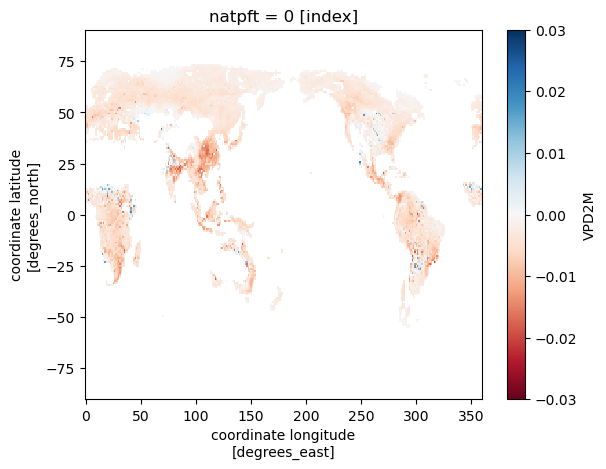

In [11]:
dif_filt.plot(vmin=-0.03,vmax=0.03,cmap="RdBu")

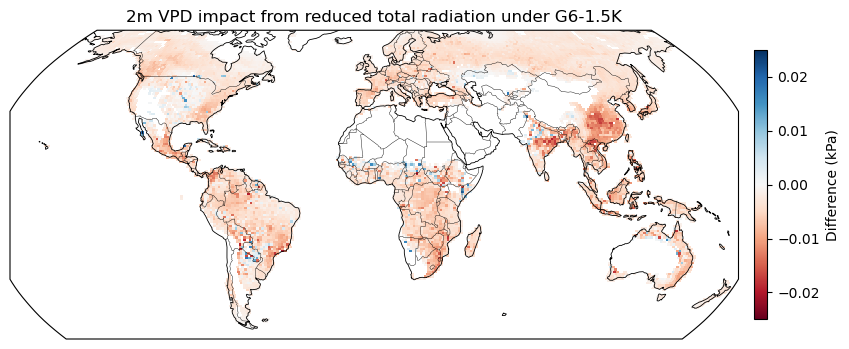

In [18]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.colors as mcolors

field = dif_filt
lon = field["lon"]
lat = field["lat"]

proj = ccrs.Robinson()

fig, ax = plt.subplots(figsize=(10, 5),
                       subplot_kw={"projection": proj})

# Ensure symmetric diverging normalization centered at 0
norm = mcolors.TwoSlopeNorm(vmin=-0.025, vcenter=0, vmax=0.025)

pcm = ax.pcolormesh(
    lon,
    lat,
    field,
    transform=ccrs.PlateCarree(),
    shading="auto",
    cmap="RdBu",
    norm=norm
)

ax.coastlines(linewidth=0.6)
ax.add_feature(cfeature.BORDERS, linewidth=0.3)
ax.set_global()
ax.set_extent([-170, 170, -60, 70], crs=ccrs.PlateCarree())

cbar = fig.colorbar(
    pcm,
    ax=ax,
    orientation="vertical",
    pad=0.02,
    fraction=0.04,
    shrink=0.7   # <– smaller = shorter
)
cbar.set_label("Difference (kPa)")


plt.title("2m VPD impact from reduced total radiation under G6-1.5K")
#plt.show()
savedir = "/glade/derecho/scratch/brendanc/fates_output/radiation"
plt.savefig(f"{savedir}/VPD_totrad_Poster.png", dpi=600, bbox_inches="tight")